# Devices

Devices (`&DEVC`) measure a quantity at a point or along a line and are written to
`CHID_devc.csv`; the heat release rate and other global values go to `CHID_hrr.csv`. This
notebook reads both.

Run FDS on `fds_steckler/steckler.fds` first: the Steckler room with thermocouples in the
room and in the door, and hot gas layer devices.

In [1]:
import matplotlib.pyplot as plt

import fdsreader as fds

sim = fds.Simulation("./fds_steckler")
sim

Simulation(chid=Steckler,
           meshes=1,
           obstructions=4,
           data_3d=5,
           smoke_3d=3,
           devices=6)

## Time series

Devices are looked up by the `ID` from the input file. Every device has its quantity, unit,
position and `data`; the device `Time` holds the output times.

In [2]:
time = sim.devices["Time"].data
hgl_temp = sim.devices["HGL Temp"]
hgl_height = sim.devices["HGL Height"]
print(hgl_temp)
print(hgl_temp.quantity.name, hgl_temp.unit, hgl_temp.data[:5])

Device(id='HGL Temp', xyz=(2.5, 1.1, 1.065), quantity=Quantity('UPPER TEMPERATURE'))
UPPER TEMPERATURE C [22.   22.01 22.05 31.3  46.86]


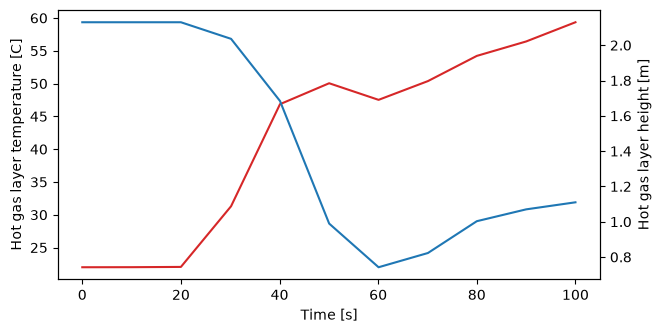

In [3]:
fig, ax1 = plt.subplots(figsize=(7, 3.5))
ax1.plot(time, hgl_temp.data, color="tab:red")
ax1.set(xlabel="Time [s]", ylabel=f"Hot gas layer temperature [{hgl_temp.unit}]")
ax2 = ax1.twinx()
ax2.plot(time, hgl_height.data, color="tab:blue")
ax2.set_ylabel(f"Hot gas layer height [{hgl_height.unit}]");

## A line of devices

A device with `POINTS` on `&DEVC` returns a list with one device per point. FDS writes these
line devices once, at the end of the simulation, so each holds a single value. Here: 38
thermocouples over the height of the door give the temperature profile through it.

38 devices, first: Device(id='TC_Door', xyz=(2.85, 0.0, 0.02), quantity=Quantity('TEMPERATURE'))


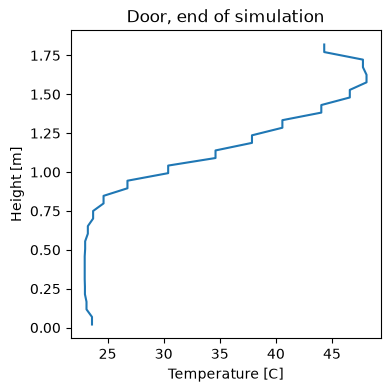

In [4]:
tc_door = sim.devices["TC_Door"]
print(len(tc_door), "devices, first:", tc_door[0])

heights = [devc.xyz[2] for devc in tc_door]
temperatures = [devc.data for devc in tc_door]

fig, ax = plt.subplots(figsize=(4, 4))
ax.plot(temperatures, heights)
ax.set(xlabel=f"Temperature [{tc_door[0].unit}]", ylabel="Height [m]", title="Door, end of simulation");

## Heat release rate

`sim.hrr` maps the columns of `CHID_hrr.csv` to arrays.

['Time', 'HRR', 'HRR_OX', 'Q_RADI', 'Q_CONV', 'Q_COND', 'Q_DIFF', 'Q_PRES', 'Q_PART', 'Q_ENTH', 'Q_TOTAL', 'MLR_AIR', 'MLR_METHANE', 'MLR_PRODUCTS']


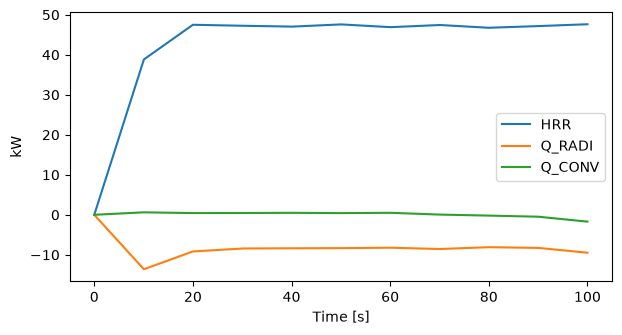

In [5]:
print(list(sim.hrr))

fig, ax = plt.subplots(figsize=(7, 3.5))
for column in ("HRR", "Q_RADI", "Q_CONV"):
    ax.plot(sim.hrr["Time"], sim.hrr[column], label=column)
ax.set(xlabel="Time [s]", ylabel="kW")
ax.legend();

## All devices as a table

With pandas installed, `to_pandas_dataframe` returns all devices with a time series as one
table, one column per device.

In [6]:
df = sim.devices.to_pandas_dataframe()
df[["Time", "HGL Temp", "HGL Height"]].head()

,Time,HGL Temp,HGL Height
0,0.00,22.000000,2.130
1,10.06,22.010000,2.130
2,20.00,22.049999,2.130
3,30.17,31.299999,2.036
4,40.09,46.860001,1.684


More in the [API reference](https://fdsreader.readthedocs.io/en/latest/api/devc.html).